# Linear Algebra for Data Science 2026 — Lab 2, Core A
# Power iteration and inverse iteration

### <div align="right"> &copy; Rostyslav Hryniv, 2026, after V. Kuchynskyi & R. Hryniv, 2023 </div>

## Completed by:
*   Vladyslav Hryhola
*   Ihor Kashuba

**Marked at the defence:** Core A is worth 2 points; the starred extensions at the end are one of three routes to the extension point (see the brief).

## Why this core

PageRank (Core B), the smoothing step in a graph neural network, and — later in the course — the leading principal component all need **one** eigenpair of a very large matrix that you can only *multiply by*. Power iteration is the algorithm that needs nothing more than $\mathbf{x}\mapsto A\mathbf{x}$. This core makes you implement it, **predict its speed before you run it**, find out where it breaks, and then use *inverse iteration with a shift* to reach the other eigenvalues.

**Uses:** Lecture 3.1 ($A^n = PD^nP^{-1}$, the Jordan asymptotics $n^k|\lambda|^n$, the role of $\kappa(P)$) and Lecture 3.2 (power iteration, inverse iteration). LU factorisation is a Module 0 prerequisite.

**Rules for this notebook**
* Inside `power_method` and `inverse_iteration` do **not** call `np.linalg.eig`, `np.linalg.eigvals`, `scipy.linalg.eig` or anything that calls them. You may use them elsewhere to *check* your results.
* Never call `np.linalg.inv` anywhere in this notebook. If you need $P^{-1}$ applied to something, solve a system.
* Every number you report must be reproduced by `Restart & Run All`.

In [1]:
import sys, numpy as np, scipy, scipy.linalg as sla, matplotlib
import matplotlib.pyplot as plt
print('python', sys.version.split()[0], '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| matplotlib', matplotlib.__version__)
rng = np.random.default_rng(2026)   # do not change the seed: the defence uses your numbers

python 3.14.6 | numpy 2.5.3 | scipy 1.18.1 | matplotlib 3.11.2


### Two provided helpers

`sin_angle(u, v)` measures how far apart two *directions* are. It ignores length and sign (and, for complex vectors, any unimodular factor), so it is the right error measure for an eigenvector.

`similar_matrix(eigvals, P)` returns $A = P\,\mathrm{diag}(\text{eigvals})\,P^{-1}$ **without** forming $P^{-1}$: from $AP = PD$ we get $P^\top A^\top = (PD)^\top$, which is one linear solve.

In [2]:
def sin_angle(u, v):
    # sine of the angle between span{u} and span{v}; accurate for small angles
    u = u / np.linalg.norm(u)
    v = v / np.linalg.norm(v)
    return np.linalg.norm(u - v * np.vdot(v, u))

def similar_matrix(eigvals, P):
    # A = P diag(eigvals) P^{-1}, computed by one solve instead of an inverse
    PD = P * np.asarray(eigvals)[None, :]          # scales column j of P by eigvals[j]
    return np.linalg.solve(P.T, PD.T).T

def random_orthogonal(n):
    Q, R = np.linalg.qr(rng.standard_normal((n, n)))
    return Q * np.sign(np.diag(R))                  # sign fix: a uniformly random orthogonal Q

---
## 1. Power iteration

### 1.1 The idea, recalled
Let $A$ be a diagonalisable $k\times k$ matrix with eigenvalues ordered so that $|\lambda_1| > |\lambda_2| \ge \dots \ge |\lambda_k|$ (so $\lambda_1$ is real and simple when $A$ is real) and eigenvectors $\mathbf{v}_1,\dots,\mathbf{v}_k$. Write $\mathbf{x}_0 = c_1\mathbf{v}_1 + \dots + c_k\mathbf{v}_k$ with $c_1 \ne 0$. Then
$$
A^n\mathbf{x}_0 = \lambda_1^n\Bigl[c_1\mathbf{v}_1 + c_2\Bigl(\tfrac{\lambda_2}{\lambda_1}\Bigr)^n\mathbf{v}_2 + \dots + c_k\Bigl(\tfrac{\lambda_k}{\lambda_1}\Bigr)^n\mathbf{v}_k\Bigr],
$$
so the direction of $A^n\mathbf{x}_0$ approaches $\mathrm{span}\{\mathbf{v}_1\}$, and the error shrinks by roughly $|\lambda_2/\lambda_1|$ per step. Normalising at each step avoids overflow:
$$
\mathbf{x}_n := \frac{A\mathbf{x}_{n-1}}{\|A\mathbf{x}_{n-1}\|}, \qquad \lambda_1 \approx \mu_n := \mathbf{x}_n^{*} A\,\mathbf{x}_n \quad(\text{the Rayleigh quotient}).
$$

**When to stop.** Do *not* stop when $\|\mathbf{x}_n - \mathbf{x}_{n-1}\|$ is small: if $\lambda_1 < 0$, the vector flips sign at every step and never settles, although its *direction* has converged. Stop instead when the **residual** is small,
$$
\|A\mathbf{x}_n - \mu_n\mathbf{x}_n\| \le \texttt{tol}\cdot\|A\|_F .
$$
(Scaling by $\|A\|_F$, computed once, makes the test independent of units. Do not divide by $\|A\mathbf{x}_n\|$ instead: that breaks down when the eigenvalue you are after is $0$.)
A small residual says that $(\mu_n, \mathbf{x}_n)$ is an exact eigenpair of a matrix very close to $A$ — the most you can ask of any floating-point method.

### 1.2 Implement `power_method`
Return the eigenvalue estimate, the unit eigenvector estimate and a history: the Rayleigh quotients and the residuals at every step. Use `np.vdot` for $\mathbf{x}^*\mathbf{y}$ so that complex input also works.

In [3]:
def power_method(A, x0=None, tol=1e-10, max_iter=1000):
    """Return (mu, x, hist) using at most max_iter products A @ x.

    Stop when ||A x - mu x|| <= tol * ||A||_F; tol=0 disables this test.
    History starts with the normalised starting vector (n=0).
    A random starting vector comes from rng when x0 is None.
    """
    # ========= YOUR CODE STARTS HERE ========= #
    A = np.asarray(A)
    x = rng.standard_normal(A.shape[0]) if x0 is None else np.array(x0, copy=True)
    if max_iter < 1 or np.linalg.norm(x) == 0:
        raise ValueError('Need max_iter >= 1 and a nonzero starting vector.')
    x = x / np.linalg.norm(x)
    scale = np.linalg.norm(A, 'fro')
    mus, residuals = [], []
    for step in range(max_iter):
        y = A @ x
        mu = np.vdot(x, y)
        res = np.linalg.norm(y - mu * x)
        mus.append(mu)
        residuals.append(res)
        if (tol > 0 and res <= tol * scale) or np.linalg.norm(y) == 0:
            break
        if step + 1 < max_iter:
            x = y / np.linalg.norm(y)
    return mu, x, {'mu': np.array(mus), 'res': np.array(residuals)}
    # ========= YOUR CODE ENDS HERE ========= #

### 1.3 Test it
The checker compares with `np.linalg.eig`. Its tolerances are matched to `tol`: a residual of $10^{-10}$ cannot give 15 correct digits, so do not tighten them.

The test matrices are chosen on purpose: `A1` has a **negative** dominant eigenvalue, `A2` is symmetric and indefinite, `A3` is non-symmetric with prescribed real eigenvalues.

In [4]:
def check_dominant(A, mu, x, rtol=1e-6):
    lam, V = np.linalg.eig(A)
    i = np.argmax(np.abs(lam))
    assert abs(mu - lam[i]) <= rtol * abs(lam[i]), f'eigenvalue {mu} vs {lam[i]}'
    assert sin_angle(x, V[:, i]) <= rtol, f'eigenvector off by sin(angle) = {sin_angle(x, V[:, i]):.1e}'
    print(f'passed: mu = {complex(mu).real:+.10f}')

A1 = np.array([[0., 1.], [-2., -3.]])
M = rng.standard_normal((6, 6)); A2 = M + M.T
A3 = similar_matrix([-5., 3., 2., 1., 0.5], rng.standard_normal((5, 5)))
for A in (A1, A2, A3):
    mu, x, hist = power_method(A)
    check_dominant(A, mu, x)
    print('   iterations:', len(hist['res']))

passed: mu = -2.0000000008
   iterations: 31
passed: mu = -5.0027417669
   iterations: 174
passed: mu = -4.9999999996
   iterations: 47


**Question 1.3.** Last year's tests used matrices `10*np.random.rand(n, n)`. Explain why even a buggy implementation that cannot cope with a negative dominant eigenvalue would pass all of those tests. *(Hint: the entries are positive; Lecture 3.2, Perron–Frobenius.)*

***Answer***

A matrix with strictly positive entries has a positive, simple dominant eigenvalue by Perron–Frobenius. So those random matrices never test a negative dominant eigenvalue. A method that incorrectly stops using the change in the vector could pass them, but fail when the vector keeps flipping sign.


### 1.4 Predict the speed, then measure it

This is the main experiment of the core. Take $k = 50$, an orthogonal $Q$, and
$$
A_r = Q\,\mathrm{diag}(1,\ r,\ \text{48 values spread evenly in } [-0.3r, 0.3r])\,Q^\top, \qquad r \in \{0.5,\ 0.9,\ 0.99\}.
$$
The dominant eigenvector is $\mathbf{v}_1 = \mathbf{q}_1$, the first column of $Q$.

**(a) Predict first.** For each $r$, how many iterations should it take for $\sin\angle(\mathbf{x}_n, \mathbf{v}_1)$ to fall from about $1$ to $10^{-8}$? Write the formula and the three numbers *before* running anything.

***Answer***

Using $r^n \approx 10^{-8}$ gives
$$n \approx \left\lceil\frac{\log(10^{-8})}{\log r}\right\rceil.$$
I predict **27, 175 and 1833** iterations for $r=0.5,0.9,0.99$. These are estimates: the starting vector changes the constant in front of $r^n$.


**(b) Measure.** Write `power_errors(A, v1, lam1, n_steps, x0)` that runs exactly `n_steps` normalised iterations from `x0` and returns two arrays: the eigenvector error $\sin\angle(\mathbf{x}_n,\mathbf{v}_1)$ and the eigenvalue error $|\mu_n - \lambda_1|$. Plot both against $n$ on a log scale for the three values of $r$, with the reference lines $r^n$. Use the **same** `x0` for all runs. Report the measured iteration counts next to your predictions.

r     predicted   measured (vector error <= 1e-8)
0.5         27         26
0.9        175        166
0.99      1833       1734


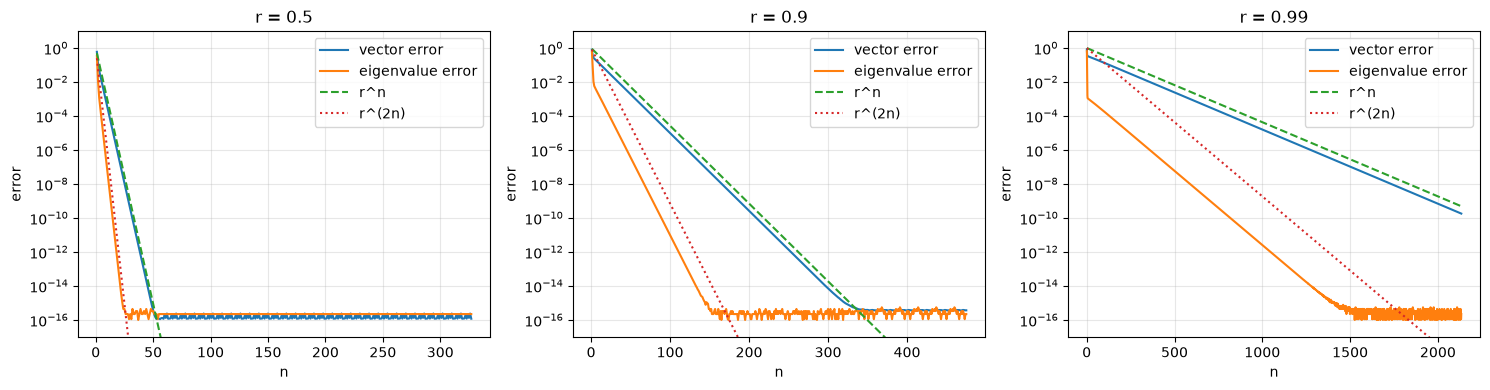

Starting coefficient ratio |c2/c1|: 0.3698625844086169


In [5]:
def power_errors(A, v1, lam1, n_steps, x0):
    # ========= YOUR CODE STARTS HERE ========= #
    x = x0 / np.linalg.norm(x0)
    vector_errors, value_errors = [], []
    for _ in range(n_steps):
        x = A @ x
        x = x / np.linalg.norm(x)
        mu = np.vdot(x, A @ x)
        vector_errors.append(sin_angle(x, v1))
        value_errors.append(abs(mu - lam1))
    return np.array(vector_errors), np.array(value_errors)
    # ========= YOUR CODE ENDS HERE ========= #

k = 50
Q = random_orthogonal(k)
x0 = rng.standard_normal(k)
# ========= YOUR CODE STARTS HERE ========= #
rs = (0.5, 0.9, 0.99)
speed_results = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
print('r     predicted   measured (vector error <= 1e-8)')
for ax, r in zip(axes, rs):
    predicted = int(np.ceil(np.log(1e-8) / np.log(r)))
    n_steps = predicted + 300
    values = np.r_[1., r, np.linspace(-0.3*r, 0.3*r, k-2)]
    A_r = (Q * values) @ Q.T
    vec_err, val_err = power_errors(A_r, Q[:, 0], 1., n_steps, x0)
    n = np.arange(1, n_steps + 1)
    measured = int(np.flatnonzero(vec_err <= 1e-8)[0] + 1)
    speed_results[r] = (A_r, vec_err, val_err, measured)
    print(f'{r:<5} {predicted:>8} {measured:>10}')
    ax.semilogy(n, vec_err, label='vector error')
    ax.semilogy(n, np.maximum(val_err, 1e-16), label='eigenvalue error')
    ax.semilogy(n, r**n, '--', label='r^n')
    ax.semilogy(n, r**(2*n), ':', label='r^(2n)')
    ax.set(title=f'r = {r}', xlabel='n', ylabel='error', ylim=(1e-17, 10))
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
print('Starting coefficient ratio |c2/c1|:', abs(Q[:, 1] @ x0 / (Q[:, 0] @ x0)))
# ========= YOUR CODE ENDS HERE ========= #

**(c) Two observations to explain.**
1. For this symmetric $A_r$ the eigenvalue error falls like $r^{2n}$ — twice as fast as the eigenvector error. You do not need to prove this (Module 4 will), but describe what you see and say why it is good news for PageRank-style uses.
2. Now repeat (b) for $r = 0.9$ only, with $A = P\,\mathrm{diag}(\dots)\,P^{-1}$ built by `similar_matrix`, where $P = U\,\mathrm{diag}(s)\,V^\top$ has orthogonal $U, V$ and singular values $s$ spread logarithmically from $1$ to $10^{-3}$, so that $\kappa(P) = 10^3$. Did the **rate** change? Did anything else change? Relate this to the role of $\kappa(P)$ in Lecture 3.1.

cond(P) = 1000.0
                         orthogonal P   ill-conditioned P
vector rate              0.900000       0.900001
eigenvalue rate          0.810013       0.899931
ill-conditioned measured count: 164
ill-conditioned |c2/c1|: 0.3178002303979007


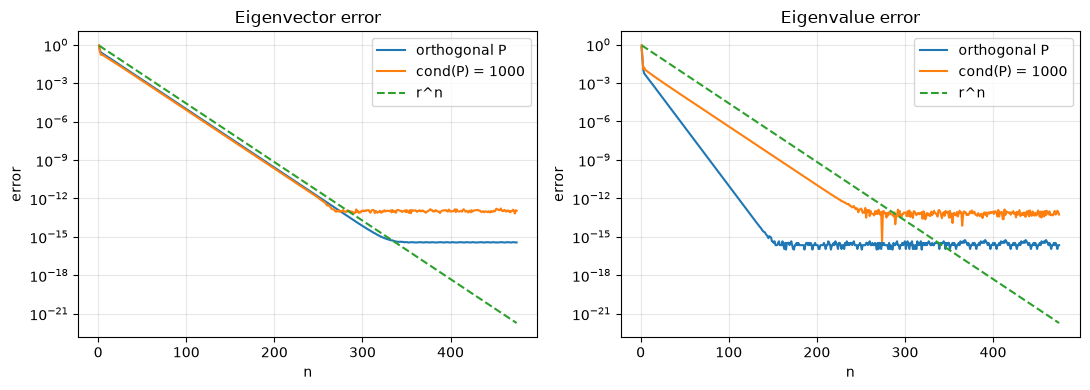

In [6]:
# ========= YOUR CODE STARTS HERE ========= #
r = 0.9
U, V = random_orthogonal(k), random_orthogonal(k)
P = (U * np.logspace(0, -3, k)) @ V.T
values = np.r_[1., r, np.linspace(-0.3*r, 0.3*r, k-2)]
A_bad = similar_matrix(values, P)
n_steps = len(speed_results[r][1])
bad_vec, bad_val = power_errors(A_bad, P[:, 0], 1., n_steps, x0)
good_vec, good_val = speed_results[r][1:3]
n = np.arange(1, n_steps + 1)

def measured_rate(errors):
    # Fit after the early steps, before rounding becomes important.
    mask = (n >= 20) & (errors > 1e-9) & (errors < 1e-3)
    return np.exp(np.polyfit(n[mask], np.log(errors[mask]), 1)[0])

print(f'cond(P) = {np.linalg.cond(P):.1f}')
print('                         orthogonal P   ill-conditioned P')
print(f'vector rate              {measured_rate(good_vec):.6f}       {measured_rate(bad_vec):.6f}')
print(f'eigenvalue rate          {measured_rate(good_val):.6f}       {measured_rate(bad_val):.6f}')
print('ill-conditioned measured count:', np.flatnonzero(bad_vec <= 1e-8)[0] + 1)
coeffs = np.linalg.solve(P, x0)
print('ill-conditioned |c2/c1|:', abs(coeffs[1] / coeffs[0]))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, good, bad, title in zip(axes, (good_vec, good_val), (bad_vec, bad_val),
                               ('Eigenvector error', 'Eigenvalue error')):
    ax.semilogy(n, np.maximum(good, 1e-16), label='orthogonal P')
    ax.semilogy(n, np.maximum(bad, 1e-16), label='cond(P) = 1000')
    ax.semilogy(n, r**n, '--', label='r^n')
    ax.set(title=title, xlabel='n', ylabel='error')
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()
# ========= YOUR CODE ENDS HERE ========= #

***Answer***

1. The measured counts are **26, 166 and 1734**, slightly below my predictions. Here $|c_2/c_1|\approx0.370$, so the late vector error is about $0.370r^n$, rather than $r^n$. The symmetric eigenvalue error follows $r^{2n}$ until rounding limits it. This means the eigenvalue can be accurate earlier, but PageRank needs the vector itself for the ranking, so a good eigenvalue alone is not enough.

2. With $\kappa(P)=1000$, the vector rate is still about **0.9000**, and the count is **164** instead of 166. The constant and the early part of the curve changed; a large $\kappa(P)$ does not mean every start takes longer. The error also levels off near $10^{-13}$ instead of about $10^{-16}$. This agrees with the lecture: $\kappa(P)$ can enlarge errors and the constant in the bound, but does not change $|\lambda_2/\lambda_1|$. The eigenvalue rate is now about **0.9000**, rather than **0.8100**: the $r^{2n}$ behavior relied on symmetry.


### 1.5 Reasons to fail
For each case below: explain *why* the method fails or slows down, give your own $3\times 3$ example, run `power_method` on it, and describe what you see (no convergence? convergence to the wrong thing? very slow convergence?). Look at `hist['res']` and `hist['mu']`, not only at the final output.

1. The dominant eigenvalues of a real matrix are a complex-conjugate pair.
2. $\lambda_1 = -\lambda_2$ (two real eigenvalues of equal modulus).
3. The dominant eigenvalue is defective: a Jordan block. *Hint:* it does converge — at what rate? Compare with the asymptotics $n^k|\lambda|^n$ from Lecture 3.1. Plot the eigenvector error, the eigenvalue error and the residual against $n$; they do **not** fall at the same rate. What does that tell you about trusting a small residual?
4. The starting vector has $c_1 = 0$. First run `power_method` with its defaults on $A = Q\,\mathrm{diag}(2,1,0.5)\,Q^\top$ (random orthogonal $Q$) and $\mathbf{x}_0 = \mathbf{q}_2$: why does it stop at once, and with what answer? Then switch the stopping test off (`tol=0`, `max_iter=120`) and compare two runs: $A = \mathrm{diag}(2, 1, 0.5)$ with $\mathbf{x}_0 = \mathbf{e}_2$, and $QDQ^\top$ with $\mathbf{x}_0 = \mathbf{q}_2$. They behave differently. Explain why, and predict roughly how many iterations the second one needs before it "notices" $\mathbf{v}_1$.

complex pair | eigenvalues: [0. +1.j 0. -1.j 0.5+0.j]
  steps=1000, mu=0.000e+00, residual=1.000e+00
  last 5 mu: [0. 0. 0. 0. 0.]
  last 5 residuals: [1. 1. 1. 1. 1.]
equal moduli | eigenvalues: [ 2. +0.j -2. +0.j  0.5+0.j]
  steps=1000, mu=0.000e+00, residual=2.000e+00
  last 5 mu: [0. 0. 0. 0. 0.]
  last 5 residuals: [2. 2. 2. 2. 2.]


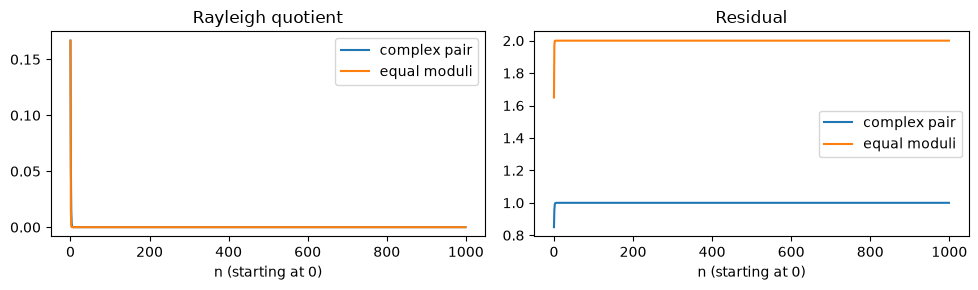

Jordan: n=999, vector error=1.001e-03, eigenvalue error=1.001e-03, residual=1.002e-06


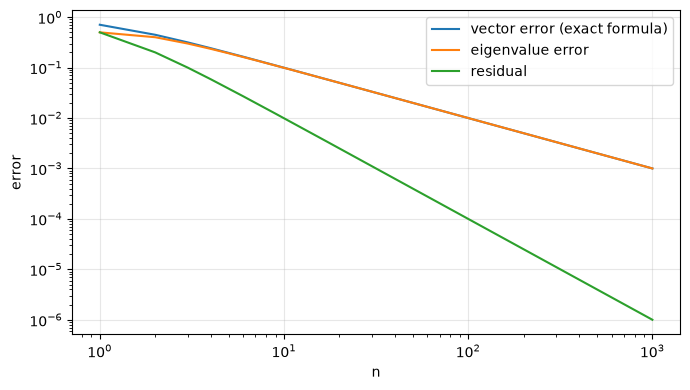

QDQ.T default: steps=1, mu=1.0000000000, residual=1.846e-16
tol=0: diagonal mu=1.0000000000; rotated mu=2.0000000000
First n with |mu - 1| > 0.1: 52
Rounding estimate log2(1/eps): 52.0


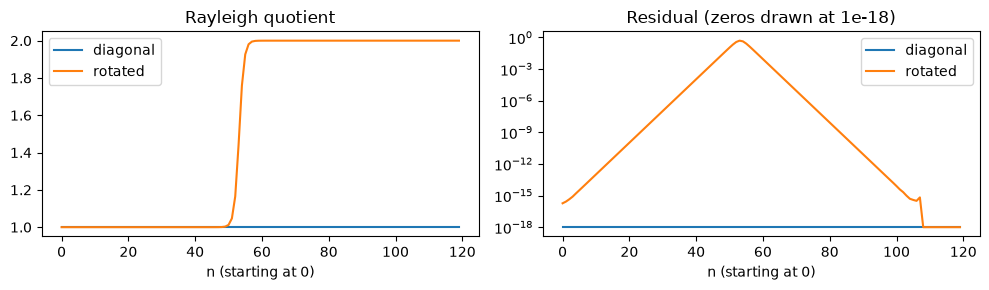

In [7]:
# ========= YOUR CODE STARTS HERE ========= #
A_complex = np.array([[0., -1., 0.], [1., 0., 0.], [0., 0., 0.5]])
A_tie = np.diag([2., -2., 0.5])
failure_runs = []
for name, A in [('complex pair', A_complex), ('equal moduli', A_tie)]:
    mu, x, hist = power_method(A, x0=np.ones(3))
    failure_runs.append((name, hist))
    print(name, '| eigenvalues:', np.linalg.eigvals(A))
    print(f'  steps={len(hist["res"])}, mu={mu:.3e}, residual={hist["res"][-1]:.3e}')
    print('  last 5 mu:', hist['mu'][-5:])
    print('  last 5 residuals:', hist['res'][-5:])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for name, hist in failure_runs:
    axes[0].plot(hist['mu'].real, label=name)
    axes[1].plot(hist['res'], label=name)
for ax, title in zip(axes, ('Rayleigh quotient', 'Residual')):
    ax.set(title=title, xlabel='n (starting at 0)')
    ax.legend()
plt.tight_layout()
plt.show()

# Jordan block: A^n e2 = (n, 1, 0), so the exact errors are known.
A_jordan = np.array([[1., 1., 0.], [0., 1., 0.], [0., 0., 0.5]])
mu_j, x_j, h_j = power_method(A_jordan, x0=np.array([0., 1., 0.]))
n_j = np.arange(len(h_j['res']))
vector_j = 1 / np.sqrt(n_j**2 + 1)
value_j = np.abs(h_j['mu'] - 1.)
residual_j = h_j['res']
print(f'Jordan: n={n_j[-1]}, vector error={sin_angle(x_j, np.array([1., 0., 0.])):.3e}, '
      f'eigenvalue error={value_j[-1]:.3e}, residual={residual_j[-1]:.3e}')
assert np.allclose(value_j, n_j / (n_j**2 + 1), atol=1e-14)
assert np.allclose(residual_j, 1 / (n_j**2 + 1), atol=1e-14)
plt.figure(figsize=(7, 4))
plt.loglog(n_j[1:], vector_j[1:], label='vector error (exact formula)')
plt.loglog(n_j[1:], value_j[1:], label='eigenvalue error')
plt.loglog(n_j[1:], residual_j[1:], label='residual')
plt.xlabel('n'); plt.ylabel('error'); plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

Q3 = random_orthogonal(3)
A_rot = (Q3 * np.array([2., 1., 0.5])) @ Q3.T
mu_wrong, x_wrong, h_wrong = power_method(A_rot, x0=Q3[:, 1])
print(f'QDQ.T default: steps={len(h_wrong["res"])}, mu={mu_wrong:.10f}, '
      f'residual={h_wrong["res"][-1]:.3e}')
mu_diag, x_diag, h_diag = power_method(np.diag([2., 1., 0.5]),
                                     x0=np.array([0., 1., 0.]), tol=0, max_iter=120)
mu_rot, x_rot, h_rot = power_method(A_rot, x0=Q3[:, 1], tol=0, max_iter=120)
print(f'tol=0: diagonal mu={mu_diag:.10f}; rotated mu={mu_rot:.10f}')
notice = np.flatnonzero(np.abs(h_rot['mu'] - 1.) > 0.1)
print('First n with |mu - 1| > 0.1:', int(notice[0]) if len(notice) else 'not reached')
print('Rounding estimate log2(1/eps):', np.log2(1 / np.finfo(float).eps))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for name, hist in [('diagonal', h_diag), ('rotated', h_rot)]:
    axes[0].plot(hist['mu'].real, label=name)
    axes[1].semilogy(np.maximum(hist['res'], 1e-18), label=name)
for ax, title in zip(axes, ('Rayleigh quotient', 'Residual (zeros drawn at 1e-18)')):
    ax.set(title=title, xlabel='n (starting at 0)')
    ax.legend()
plt.tight_layout(); plt.show()
# ========= YOUR CODE ENDS HERE ========= #

***Answer***

1. My rotation example has eigenvalues $i,-i,0.5$. The first two components keep rotating and neither eigenvalue dominates. After 1000 checks the Rayleigh quotient is 0 and the residual is 1, so the method has not converged to an eigenpair.

2. For $\operatorname{diag}(2,-2,0.5)$, the first two components have equal size and one changes sign each step. With my start, the quotient tends to 0 while the residual tends to 2. Equal moduli give no decay of one leading component relative to the other.

3. For my Jordan block, $A^n e_2=(n,1,0)^T$. Thus
$$\sin\angle(x_n,e_1)=\frac1{\sqrt{n^2+1}},\qquad
|\mu_n-1|=\frac{n}{n^2+1},\qquad
\|Ax_n-\mu_nx_n\|=\frac1{n^2+1}.$$
The vector and eigenvalue errors fall like $1/n$, while the residual falls like $1/n^2$. At $n=999$, the first two errors are about $10^{-3}$, but the residual is about $10^{-6}$. A small residual therefore does not guarantee an equally small eigenvector error for a defective matrix.

4. With $x_0=q_2$, the default run stops after one check at eigenvalue **1**: it is already an eigenpair, with residual about $1.85\times10^{-16}$. A residual test cannot tell whether it is the dominant one. With `tol=0`, the diagonal example stays exactly at $e_2$ and eigenvalue 1. In the rotated example, rounding introduces a tiny $q_1$ component. Its size relative to $q_2$ doubles each step, so a component of order $\varepsilon$ becomes visible after about $\log_2(1/\varepsilon)=52$ steps. The measured quotient first differs from 1 by more than 0.1 at $n=52$, and eventually approaches 2.

`power_method` records the starting vector at $n=0$; its history length counts matrix-vector products. The plots above use this convention.


---
## 2. Inverse iteration with a shift

### 2.1 The idea
If $A\mathbf{v} = \lambda\mathbf{v}$ then $(A - \mu I)^{-1}\mathbf{v} = (\lambda - \mu)^{-1}\mathbf{v}$. So the eigenvalue of $A$ **closest to the shift** $\mu$ becomes the *dominant* eigenvalue of $(A-\mu I)^{-1}$, and power iteration on $(A-\mu I)^{-1}$ finds it. The per-step rate is
$$
\frac{|\lambda_* - \mu|}{|\lambda_{**} - \mu|},
$$
where $\lambda_*$ is the closest eigenvalue and $\lambda_{**}$ the second-closest.

You never form $(A-\mu I)^{-1}$. Each step **solves** $(A - \mu I)\mathbf{y} = \mathbf{x}_{n-1}$. Factorise $A - \mu I = LU$ once with `scipy.linalg.lu_factor`, then call `scipy.linalg.lu_solve` at every step.

### 2.2 Implement `inverse_iteration`
Return the eigenvalue **of $A$** (the Rayleigh quotient $\mathbf{x}^*A\mathbf{x}$, not of the inverse), the unit eigenvector and the same history as before, with the same residual stopping rule applied to $A$.

In [8]:
def inverse_iteration(A, mu, x0=None, tol=1e-10, max_iter=500):
    """Return (lam, x, hist) for the eigenvalue nearest the shift mu.

    Factor A - mu I once. Each history entry follows one solve.
    Stop when ||A x - lam x|| <= tol * ||A||_F; tol=0 disables stopping.
    A random starting vector comes from rng when x0 is None.
    """
    # ========= YOUR CODE STARTS HERE ========= #
    A = np.asarray(A)
    x = rng.standard_normal(A.shape[0]) if x0 is None else np.array(x0, copy=True)
    if max_iter < 1 or np.linalg.norm(x) == 0:
        raise ValueError('Need max_iter >= 1 and a nonzero starting vector.')
    x = x / np.linalg.norm(x)
    scale = np.linalg.norm(A, 'fro')
    lu, piv = sla.lu_factor(A - mu * np.eye(A.shape[0]))
    lams, residuals = [], []
    for _ in range(max_iter):
        y = sla.lu_solve((lu, piv), x)
        x = y / np.linalg.norm(y)
        Ax = A @ x
        lam = np.vdot(x, Ax)
        res = np.linalg.norm(Ax - lam * x)
        lams.append(lam)
        residuals.append(res)
        if tol > 0 and res <= tol * scale:
            break
    return lam, x, {'mu': np.array(lams), 'res': np.array(residuals)}
    # ========= YOUR CODE ENDS HERE ========= #

**Question 2.2.** State the cost of your implementation in flops, to leading order, for a $k\times k$ matrix and $m$ iterations. Compare with (i) calling `np.linalg.solve(A - mu*I, x)` inside the loop and (ii) forming `inv(A - mu*I)` once and multiplying. Why is (ii) still worse than your version, even though its cost per step is also $O(k^2)$?

***Answer***

For real arithmetic, LU costs about $\frac23 k^3$ flops once. Each iteration costs about $2k^2$ for the two triangular solves and $2k^2$ for $Ax$ to check the residual. The total is about $\frac23 k^3+4mk^2$, ignoring smaller terms.

1. Calling `solve` each time repeats the factorisation: about $\frac23 mk^3+4mk^2$.
2. Forming the inverse also gives $O(k^3+mk^2)$ overall, but needs extra work to compute all its columns and adds rounding error. LU directly solves for the one vector we need, so the inverse is unnecessary.


### 2.3 Find all eigenvalues of a test matrix
Let $D = \mathrm{diag}(0, 1, \dots, 9)$, let $P$ be a random $10\times10$ matrix, and $A = PDP^{-1}$ (use `similar_matrix`).

**(a)** Explain why the diagonal entries of $D$ are the eigenvalues of $A$ and the columns of $P$ are corresponding eigenvectors.

**(b)** With the shifts $\mu_j = j + 0.3$, $j = 0,\dots,9$, find all ten eigenpairs. Check each against the corresponding column of $P$ with `sin_angle`.

**(c)** Predict the per-step rate for $\mu = j + 0.3$ and for $\mu = j + 0.49$, then measure both for one $j$ of your choice from the history. Which eigenvalue does $\mu = j + 0.5$ find, and why is that shift a bad idea?

***Answer***

**(a)** From $A=PDP^{-1}$ we get $AP=PD$. Column $j$ therefore satisfies $Ap_j=j p_j$, so $0,\ldots,9$ are the eigenvalues and the columns of $P$ are their eigenvectors.

**(c), prediction.** I choose $j=4$. The rate is $0.3/0.7\approx0.4286$ for shift $4.3$, and $0.49/0.51\approx0.9608$ for shift $4.49$. At $4.5$, eigenvalues 4 and 5 are equally close. Neither is selected uniquely: their inverse eigenvalues have equal magnitude and opposite signs, so a general start does not converge to one direction.


j     estimate        solves     sin(angle)       residual
0   0.0000000040      25       3.266e-09       3.266e-09
1   1.0000000003      26       1.990e-09       1.990e-09
2   2.0000000008      22       2.803e-09       2.803e-09
3   3.0000000003      25       1.683e-09       1.683e-09
4   3.9999999993      25       1.901e-09       1.901e-09
5   4.9999999987      22       1.911e-09       1.911e-09
6   6.0000000003      23       1.857e-09       1.857e-09
7   7.0000000004      23       2.061e-09       2.061e-09
8   7.9999999986      24       3.324e-09       3.324e-09
9   8.9999999996      14       8.382e-10       8.380e-10


shift=4.3: measured residual rate=0.428559, solves=24
shift=4.49: measured residual rate=0.960784, solves=492


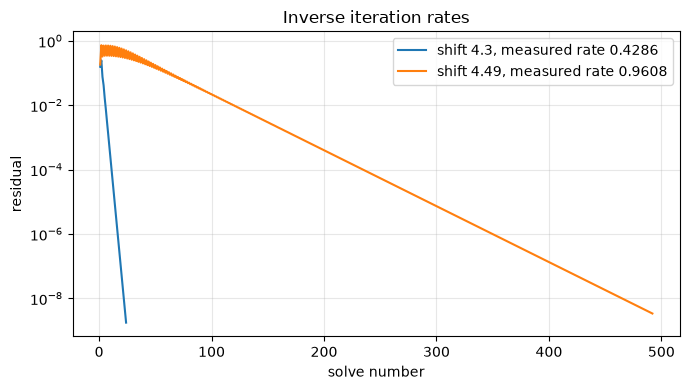

In [9]:
D_vals = np.arange(10.)
P10 = rng.standard_normal((10, 10))
A10 = similar_matrix(D_vals, P10)
# ========= YOUR CODE STARTS HERE ========= #
print('j     estimate        solves     sin(angle)       residual')
all_pairs = []
for j in range(10):
    lam, x, hist = inverse_iteration(A10, j + 0.3)
    angle = sin_angle(x, P10[:, j])
    all_pairs.append((lam, x, hist))
    print(f'{j}  {lam: .10f}    {len(hist["res"]):>4}       {angle:.3e}       {hist["res"][-1]:.3e}')
    assert abs(lam - j) < 1e-6 and angle < 1e-6
    assert hist['res'][-1] <= 1e-10 * np.linalg.norm(A10, 'fro')

shift_x0 = rng.standard_normal(10)
fig, ax = plt.subplots(figsize=(7, 4))
shift_rates = {}
for shift in (4.3, 4.49):
    lam, x, hist = inverse_iteration(A10, shift, x0=shift_x0, max_iter=1500)
    residuals = hist['res']
    n_shift = np.arange(1, len(residuals) + 1)
    mask = (n_shift >= 10) & (residuals > 1e-7) & (residuals < 1e-3)
    rate = np.exp(np.polyfit(n_shift[mask], np.log(residuals[mask]), 1)[0])
    shift_rates[shift] = rate
    print(f'shift={shift}: measured residual rate={rate:.6f}, solves={len(residuals)}')
    ax.semilogy(n_shift, residuals, label=f'shift {shift}, measured rate {rate:.4f}')
ax.set(xlabel='solve number', ylabel='residual', title='Inverse iteration rates')
ax.legend(); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()
# ========= YOUR CODE ENDS HERE ========= #

***Answer***

**(b)** All ten estimates pass the eigenvalue and angle checks. They take 14–26 solves, with eigenvector errors below $3.4\times10^{-9}$. The estimate for eigenvalue 0 is about $4.0\times10^{-9}$, so I check it using absolute error.

**(c), measurement.** The measured residual rates are **0.428559** and **0.960784**, close to the predictions. The two shifts need **24** and **492** solves from the same starting vector. Moving the shift toward the midpoint makes the two closest eigenvalues compete and slows convergence.


### 2.4 A shift that is *too* good
Take $\mu = 4 + 10^{-12}$. Compute $\kappa(A_{10} - \mu I)$ with `np.linalg.cond`. By everything you learned in Modules 1–2, solving with this matrix should be hopeless. Run `inverse_iteration` anyway and report the number of iterations and the accuracy of the eigenvector. Then explain, in your own words, why the huge condition number does no harm here. *(Hint: the solution $\mathbf{y}$ is badly wrong in length; in which direction is it wrong?)*

In [10]:
# ========= YOUR CODE STARTS HERE ========= #
close_shift = 4 + 1e-12
shift_cond = np.linalg.cond(A10 - close_shift * np.eye(10))
close_x0 = rng.standard_normal(10)
lam_close, x_close, h_close = inverse_iteration(A10, close_shift, x0=close_x0)
close_angle = sin_angle(x_close, P10[:, 4])
print(f'cond(A10 - mu I) = {shift_cond:.3e}')
print(f'solves = {len(h_close["res"])}')
print(f'eigenvalue = {lam_close:.15f}, eigenvalue error = {abs(lam_close - 4):.3e}')
print(f'sin(angle) = {close_angle:.3e}')
print('residual history:', h_close['res'])
assert close_angle < 1e-8
lam_two, x_two, h_two = inverse_iteration(A10, close_shift, x0=close_x0, tol=0, max_iter=2)
print(f'After exactly two solves: sin(angle) = {sin_angle(x_two, P10[:, 4]):.3e}, '
      f'eigenvalue error = {abs(lam_two - 4):.3e}')
# ========= YOUR CODE ENDS HERE ========= #

cond(A10 - mu I) = 8.618e+13
solves = 1
eigenvalue = 4.000000000000838, eigenvalue error = 8.376e-13
sin(angle) = 2.960e-12
residual history: [7.31311168e-13]
After exactly two solves: sin(angle) = 6.429e-16, eigenvalue error = 4.441e-16


***Answer***

The condition number is about $8.62\times10^{13}$. With the default tolerance, only **one solve** is needed: the eigenvector error is about $2.96\times10^{-12}$ and the eigenvalue error about $8.38\times10^{-13}$. The extra run above uses exactly two solves to compare with the description's two-step result.

The component along the eigenvector for 4 is multiplied by about $10^{12}$, while the other components are much smaller. Rounding can badly affect the length of this large solution, but its direction is still close to the wanted eigenvector. Normalising removes the length error. This explains this result; it does not mean every ill-conditioned solve is accurate.


---
## 3. Conclusions
In a few sentences: what did you learn, what was harder than expected, and which result surprised you? If you hit a wall you could not get past, describe it here **and** in your `README` — an explained wall is worth more at the defence than a clean output you cannot explain.

***Answer***

I learned that the eigenvalue ratio predicts the speed well, but the starting vector affects the iteration count. The hardest part was separating a small residual from an accurate eigenvector: the Jordan example shows they can be quite different. The close shift surprised me because normalisation still gives an accurate direction despite the huge condition number. I would check the residual and the convergence history together when using these methods.


---
# ★ Extensions
Do **at most one** extension for the whole lab (A1, A2 here, or B1 in the Core B notebook). The point is awarded for **a defended finding**: end your extension with a short paragraph headed *Finding* that states what you found and why.

## ★ A1. The QR algorithm: what `np.linalg.eig` builds on
Starting from $A_1 = A$, repeat: factor $A_k = Q_kR_k$, set $A_{k+1} := R_kQ_k$. Under mild assumptions $A_k$ tends to an upper-triangular matrix with the eigenvalues of $A$ on the diagonal.

1. Show that every $A_{k+1}$ is similar to $A_k$ (write $A_{k+1}$ as $Q_k^\top A_k Q_k$), so the eigenvalues never change.
2. Implement the **unshifted** method (`np.linalg.qr` is allowed). Stop when the largest entry below the diagonal is below $10^{-10}\|A\|_F$. Run it on $A = Q\,\mathrm{diag}(1,2,\dots,10)\,Q^\top$. Count the iterations. Predict that count from the ratios $\lambda_{i+1}/\lambda_i$ before you run it. *(Hint: the unshifted method behaves like power iteration on all columns at once.)*
3. Implement a **shifted** version with deflation: on the active $m\times m$ block, use $\mu = a_{mm}$, factor $A_k - \mu I = QR$, set $A_{k+1} = RQ + \mu I$; when $|a_{m,m-1}|$ is negligible, accept $a_{mm}$ and continue with the leading $(m-1)\times(m-1)$ block. Count the total iterations on the same $A$, and record $|a_{m,m-1}|$ step by step for one eigenvalue. How fast does it fall — do the correct digits roughly double, or more?
4. Run the unshifted method on a real matrix whose dominant eigenvalues are a complex pair. What does $A_k$ look like after many steps? Connect this with failure case 1 of §1.5.

In [ ]:
# YOUR CODE HERE

## ★ A2. Stable, yet it grows: non-normal iterated maps
An iterated map $\mathbf{x}_{n+1} = A\mathbf{x}_n$ with spectral radius $\rho(A) < 1$ always tends to $\mathbf{0}$. It need **not** get there monotonically. This matters whenever a linear recurrence is called "stable" because its eigenvalues are inside the unit circle — a linear RNN or an autoregressive model, for example.

1. Take $A = \begin{pmatrix} 0.95 & 10 \\ 0 & 0.9\end{pmatrix}$. Plot $\|A^n\|_2$ for $n = 0,\dots,200$ together with $\rho(A)^n$ and the bound $\kappa(P)\,\rho(A)^n$ from Lecture 3.1 ($P$ the eigenvector matrix; here you may use `np.linalg.eig`). Find the peak of $\|A^n\|_2$ and the $n$ where it happens.
2. Derive $A^n$ in closed form for this triangular $A$ and use it to explain the peak.
3. Repeat for the $20\times20$ bidiagonal matrix with $0.9$ on the diagonal and $1$ on the superdiagonal. How large does $\|A^n\|_2$ get before it decays? Why is $\kappa(P)$ useless as a bound here?

In [ ]:
# YOUR CODE HERE